# EN3160 - Assignment 02: Fitting and Alignment

**Name:** Eranga W.A.O.                                                                                                                              
**Index number:** 230175U 

In [52]:
from pathlib import Path

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import minimize


In [ ]:
image_dir = Path('a2images')
SAVE_FIGURES = False
output_dir = Path('results')

if SAVE_FIGURES:
    output_dir.mkdir(exist_ok=True)

plt.rcParams['figure.figsize'] = (9, 6)
plt.rcParams['font.size'] = 11
cv.setRNGSeed(0)


In [54]:
def read_image(path, flag=cv.IMREAD_COLOR):
    image = cv.imread(str(path), flag)
    if image is None:
        raise FileNotFoundError(f'Could not read {path}')
    return image


def show_image(ax, image, title):
    if image.ndim == 2:
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    else:
        ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')


def save_figure(fig, name):
    if SAVE_FIGURES:
        fig.savefig(output_dir / name, dpi=200, bbox_inches='tight')


## 1. Sunflower detection using Laplacian of Gaussian


#### 1.1 Read the sunflower image

Read the reduced image and convert it to grayscale values between 0 and 1.


In [55]:
sunflowers = read_image(
    image_dir / 'the_berry_farms_sunflower_field.jpeg',
    cv.IMREAD_REDUCED_COLOR_4
)
gray = cv.cvtColor(sunflowers, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
height, width = gray.shape


#### 1.2 Build the LoG scale space

Keep the positive scale-normalized response to detect dark flower centres.


In [56]:
sigmas = np.geomspace(1.5, 20.0, 32)
responses = np.zeros((len(sigmas), height, width), dtype=np.float32)

for i, sigma in enumerate(sigmas):
    log_response = sigma**2 * gaussian_laplace(gray, sigma=sigma)
    responses[i] = np.maximum(log_response, 0)


#### 1.3 Find maxima in space and scale

Search below the horizon and keep peaks above 15% of the strongest positive field response.


In [57]:
local_max = maximum_filter(responses, size=(3, 3, 3), mode='nearest')
field_start = int(0.50 * height)
response_threshold = 0.15 * responses[:, field_start:, :].max()
peak_mask = (responses == local_max) & (responses > response_threshold)
peak_mask[:, :field_start, :] = False

# A scale maximum needs neighbouring scales on both sides.
peak_mask[0] = False
peak_mask[-1] = False
peak_locations = np.argwhere(peak_mask)


#### 1.4 Check for a dark centre surrounded by yellow petals


In [58]:
hsv = cv.cvtColor(sunflowers, cv.COLOR_BGR2HSV)
yellow_mask = cv.inRange(hsv, (15, 100, 100), (40, 255, 255)) > 0
max_centre_intensity = 0.45
min_contrast = 0.10
min_yellow_fraction = 0.30
min_quadrant_fraction = 0.20


def has_flower_petals(x, y, radius):
    margin = int(np.ceil(2.0 * radius))
    if x - margin < 0 or x + margin >= width or y - margin < 0 or y + margin >= height:
        return False

    patch = gray[y-margin:y+margin+1, x-margin:x+margin+1]
    yellow = yellow_mask[y-margin:y+margin+1, x-margin:x+margin+1]
    yy, xx = np.mgrid[-margin:margin+1, -margin:margin+1]
    distances = np.hypot(xx, yy)
    centre = distances <= 0.55 * radius
    ring = (distances >= 1.15 * radius) & (distances <= 2.0 * radius)

    centre_mean = patch[centre].mean()
    if centre_mean > max_centre_intensity or patch[ring].mean() - centre_mean < min_contrast:
        return False
    if yellow[ring].mean() < min_yellow_fraction:
        return False

    quadrants = [(xx >= 0) & (yy >= 0), (xx < 0) & (yy >= 0),
                 (xx < 0) & (yy < 0), (xx >= 0) & (yy < 0)]
    supported = 0
    for quadrant in quadrants:
        part = ring & quadrant
        if part.any() and yellow[part].mean() >= min_quadrant_fraction:
            supported += 1
    return supported >= 3


#### 1.4(b) Apply the petal check to the LoG candidates

The centre and radius still come from the LoG peak; the colour and contrast checks only reject candidates.


In [59]:
candidates = []
for scale_index, y, x in peak_locations:
    radius = np.sqrt(2) * sigmas[scale_index]
    if not has_flower_petals(x, y, radius):
        continue
    score = responses[scale_index, y, x]
    candidates.append((float(x), float(y), float(radius),
                       float(sigmas[scale_index]), float(score)))

print(f'LoG peaks before filtering: {len(peak_locations)}')
print(f'Candidates passing the petal check: {len(candidates)}')

LoG peaks before filtering: 427
Candidates passing the petal check: 182


#### 1.5 Remove duplicate detections

Keep the stronger overlapping detections, then sort the remaining circles by radius.


In [60]:
# Keep the stronger response when two circles describe the same neighbourhood.
candidates.sort(key=lambda item: item[4], reverse=True)
circles = []
for candidate in candidates:
    x, y, radius, sigma, score = candidate
    duplicate = False
    for old_x, old_y, old_radius, _, _ in circles:
        distance = np.hypot(x - old_x, y - old_y)
        if distance < 0.75 * (radius + old_radius):
            duplicate = True
            break
    if not duplicate:
        circles.append(candidate)

circles.sort(key=lambda item: item[2], reverse=True)
print(f'Sigma range: {sigmas[0]:.2f} to {sigmas[-1]:.2f} pixels')
print(f'Number of scales: {len(sigmas)}')
print(f'Positive LoG threshold: {response_threshold:.6f}')
print(f'Number of circles: {len(circles)}')


Sigma range: 1.50 to 20.00 pixels
Number of scales: 32
Positive LoG threshold: 0.060591
Number of circles: 140


#### 1.6 Draw the detected circles

The five largest circles are shown in red and numbered.


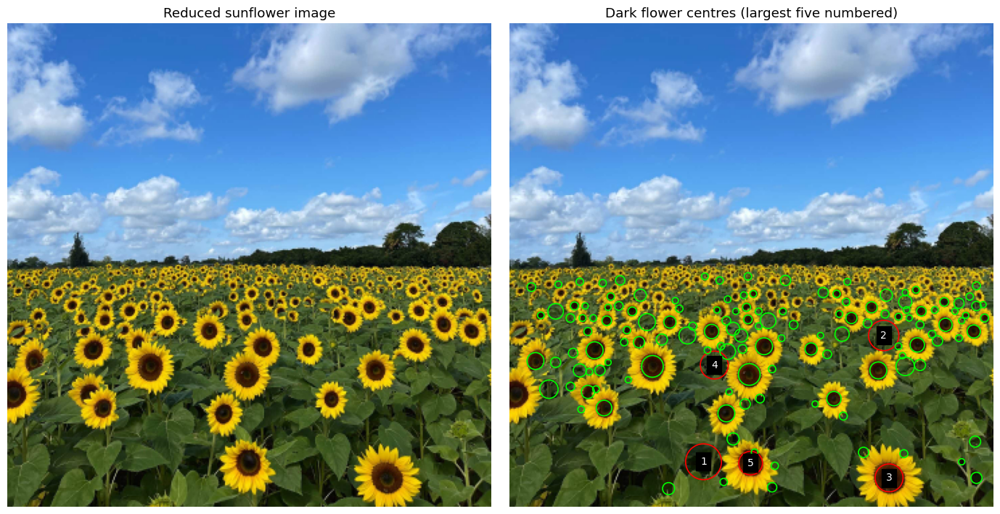

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
show_image(axes[0], sunflowers, 'Reduced sunflower image')
show_image(axes[1], sunflowers, 'Dark flower centres (largest five numbered)')

for i, (x, y, radius, sigma, score) in enumerate(circles):
    colour = 'red' if i < 5 else 'lime'
    axes[1].add_patch(plt.Circle((x, y), radius, fill=False,
                               color=colour, linewidth=1.2))
    if i < 5:
        axes[1].text(x, y, str(i + 1), color='white', fontsize=10,
                     ha='center', va='center', backgroundcolor='black')

fig.tight_layout()
save_figure(fig, 'q1_sunflower_circles.png')
plt.show()


#### 1.7 Report the largest circle parameters

Print the centre, radius and sigma for the five largest detections.


In [62]:
print('Largest dark-centre circles: coordinates are (x, y), measured from the top left.')
print(f'{"No.":>4} {"x":>9} {"y":>9} {"radius":>9} {"sigma":>9}')
for i, (x, y, radius, sigma, score) in enumerate(circles[:5], start=1):
    print(f'{i:4d} {x:9.2f} {y:9.2f} {radius:9.2f} {sigma:9.2f}')

if not circles:
    print('No circles passed the filters. Inspect the image before adjusting the LoG, colour or contrast thresholds.')


Largest dark-centre circles: coordinates are (x, y), measured from the top left.
 No.         x         y    radius     sigma
   1    144.00    326.00     13.33      9.43
   2    278.00    232.00     11.28      7.98
   3    282.00    338.00     10.38      7.34
   4    152.00    254.00     10.38      7.34
   5    179.00    327.00      8.78      6.21


**Discussion.** The circles represent dark sunflower centres, not the complete petal outlines.
The reported coordinates, radii and sigmas use pixels of the reduced image. Multiplying a length
by four gives the corresponding length in the original 1440 x 1440 image.

Keeping one LoG polarity removes bright-petal peaks. Requiring yellow petals in several directions
reduces detections on foliage next to a flower. These checks can miss very small, shaded, tilted
or partly hidden flowers. Candidates whose surrounding ring reaches outside the image are also
excluded. The detector does not provide a complete flower count.

The earlier run returned 359 circles and included false detections on the background. Those outputs
have been cleared because the detector has changed. Inspect the new plot, especially the five
numbered circles, before accepting their measurements. The revised filtering has not yet been
verified by execution.


## 2. Line and circle fitting using RANSAC

### Generate the noisy points

This uses the same distributions and parameters as Listing 1. A fixed random seed makes the
point set repeatable. The true model labels are used only for plotting and later comparison,
not to select the RANSAC inliers.

#### Generate the noisy circle points

Use the given centre, radius and radial noise.


In [63]:
rng = np.random.default_rng(0)
N = 100
half_n = N // 2

r_gt = 10.0
x0_gt, y0_gt = 2.0, 3.0
circle_noise = r_gt / 16
t = rng.uniform(0, 2 * np.pi, half_n)
n = circle_noise * rng.standard_normal(half_n)
x = x0_gt + (r_gt + n) * np.cos(t)
y = y0_gt + (r_gt + n) * np.sin(t)
X_circ = np.column_stack((x, y))


#### Generate the noisy line points

Add vertical noise to the line and combine both point sets into X.


In [64]:
m_gt, b_gt = -1.0, 2.0
line_noise = 1.0
x = np.linspace(-12, 12, half_n)
y = m_gt * x + b_gt + line_noise * rng.standard_normal(half_n)
X_line = np.column_stack((x, y))
X = np.vstack((X_circ, X_line))


#### Plot the generated data

Compare the noisy points with the two ground-truth models.


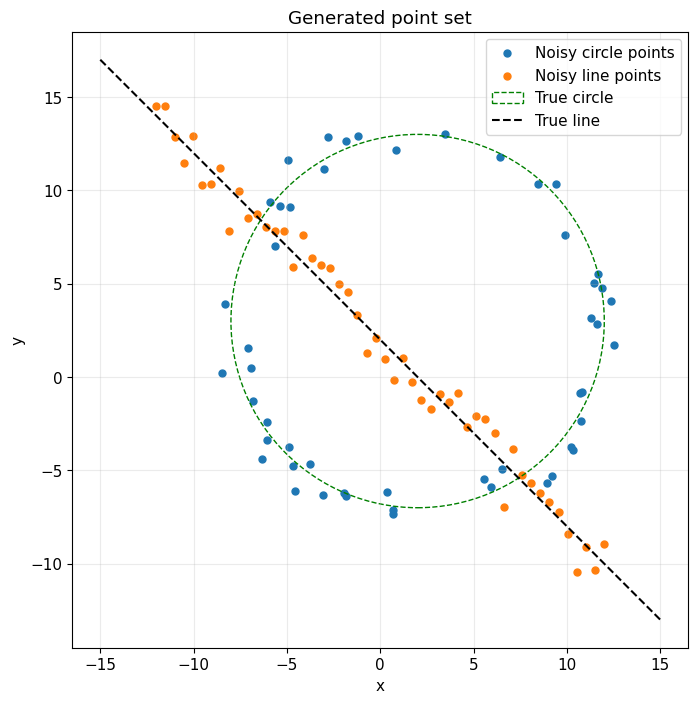

In [65]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X_circ[:, 0], X_circ[:, 1], s=25, label='Noisy circle points')
ax.scatter(X_line[:, 0], X_line[:, 1], s=25, label='Noisy line points')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, fill=False,
                        color='green', linestyle='--', label='True circle'))
x_plot = np.linspace(-15, 15, 300)
ax.plot(x_plot, m_gt * x_plot + b_gt, 'k--', label='True line')
ax.set(xlabel='x', ylabel='y', title='Generated point set')
ax.set_aspect('equal')
ax.grid(alpha=0.25)
ax.legend()
plt.show()


### 2(a). RANSAC line

#### 2(a).1 Calculate the number of RANSAC trials

This function implements the trial-count formula above.


In [66]:
def ransac_trials(inlier_fraction, sample_size, confidence=0.999):
    return int(np.ceil(np.log(1 - confidence) /
                       np.log(1 - inlier_fraction**sample_size)))


#### 2(a).2 Define a line and its error

Build a unit-normal line from two points, then measure perpendicular distances.


In [67]:
def line_from_two_points(points):
    p1, p2 = points
    direction = p2 - p1
    length = np.linalg.norm(direction)
    if length < 1e-10:
        return None

    normal = np.array([-direction[1], direction[0]]) / length
    d = normal @ p1
    if d < 0:
        normal = -normal
        d = -d
    return np.array([normal[0], normal[1], d])


def line_errors(points, model):
    a, b, d = model
    return np.abs(a * points[:, 0] + b * points[:, 1] - d)


#### 2(a).3 Define the total least squares fit

Fit the final line to all points in a consensus set.


In [68]:
def fit_line_tls(points):
    centre = points.mean(axis=0)
    U = points - centre
    eigenvalues, eigenvectors = np.linalg.eigh(U.T @ U)
    normal = eigenvectors[:, np.argmin(eigenvalues)]
    normal = normal / np.linalg.norm(normal)
    d = normal @ centre
    if d < 0:
        normal = -normal
        d = -d
    return np.array([normal[0], normal[1], d])


#### 2(a).4 Define the line RANSAC algorithm

Repeat sampling, error calculation and consensus selection. Keep this function together as one cell.


In [69]:
def ransac_line(points, threshold, min_inliers, n_trials, seed=1):
    if len(points) < max(2, min_inliers):
        raise ValueError('Too few points for the required line consensus.')
    random = np.random.default_rng(seed)
    best_count = 0
    best_error = np.inf
    best_mask = None

    for _ in range(n_trials):
        indices = random.choice(len(points), size=2, replace=False)
        sample = points[indices]
        model = line_from_two_points(sample)
        if model is None:
            continue

        errors = line_errors(points, model)
        mask = errors < threshold
        count = int(mask.sum())
        if count < min_inliers:
            continue
        mean_error = np.mean(errors[mask]**2)

        if count > best_count or (count == best_count and mean_error < best_error):
            best_count = count
            best_error = mean_error
            best_mask = mask.copy()
            best_sample = sample.copy()
            best_sample_model = model.copy()

    if best_mask is None:
        raise ValueError('No line reached the minimum consensus. Check the parameters.')

    # Keep the winning consensus fixed while refitting, so the fit and sample can be compared.
    best_fit = fit_line_tls(points[best_mask])
    return {'model': best_fit, 'sample_model': best_sample_model,
            'sample': best_sample, 'inliers': best_mask}


#### 2(a).5 Fit the line

Choose the thresholds and call the RANSAC function.


In [70]:
line_threshold = 1.4
line_min_inliers = 35
line_n_trials = max(500, ransac_trials(0.35, 2))

line_result = ransac_line(X, line_threshold, line_min_inliers, line_n_trials)
line_model = line_result['model']
line_inliers = line_result['inliers']
a, b, d = line_model


#### 2(a).6 Inspect the line parameters

Check the normal length, consensus size and perpendicular error.


In [71]:
print(f'Line trials: {line_n_trials}')
print(f'Best-fit line: {a:.5f} x + {b:.5f} y = {d:.5f}')
print(f'Normal length: {np.hypot(a, b):.6f}')
print(f'Winning line consensus: {line_inliers.sum()} points')
print(f'Perpendicular RMSE on that consensus: '
      f'{np.sqrt(np.mean(line_errors(X[line_inliers], line_model)**2)):.4f}')


Line trials: 500
Best-fit line: 0.71710 x + 0.69697 y = 1.46671
Normal length: 1.000000
Winning line consensus: 57 points
Perpendicular RMSE on that consensus: 0.7129


### 2(b). RANSAC circle after removing the line consensus

#### 2(b).1 Define a circle through three points

Solve for the circumcentre and reject nearly collinear samples.


In [72]:
def circle_from_three_points(points):
    p1, p2, p3 = points
    A = 2 * np.vstack((p2 - p1, p3 - p1))
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])

    # Nearly collinear points give an unstable circumcircle.
    if np.linalg.cond(A) > 1e6:
        return None
    centre = np.linalg.solve(A, rhs)
    radius = np.linalg.norm(p1 - centre)
    model = np.array([centre[0], centre[1], radius])
    if not np.all(np.isfinite(model)) or radius <= 0:
        return None
    return model


#### 2(b).2 Define radial error and the fitting objective

The optimizer will minimize the sum of squared radial errors.


In [73]:
def circle_errors(points, model):
    xc, yc, radius = model
    distances = np.hypot(points[:, 0] - xc, points[:, 1] - yc)
    return np.abs(distances - radius)


def circle_objective(model, points):
    errors = circle_errors(points, model)
    return np.sum(errors**2)


#### 2(b).3 Define the circle RANSAC algorithm

Select the strongest consensus, then refine its centre and radius.


In [74]:
def ransac_circle(points, threshold, min_inliers, n_trials, seed=2):
    if len(points) < max(3, min_inliers):
        raise ValueError('Too few points for the required circle consensus.')
    random = np.random.default_rng(seed)
    best_count = 0
    best_error = np.inf
    best_mask = None

    for _ in range(n_trials):
        indices = random.choice(len(points), size=3, replace=False)
        sample = points[indices]
        model = circle_from_three_points(sample)
        if model is None:
            continue

        errors = circle_errors(points, model)
        mask = errors < threshold
        count = int(mask.sum())
        if count < min_inliers:
            continue
        mean_error = np.mean(errors[mask]**2)

        if count > best_count or (count == best_count and mean_error < best_error):
            best_count = count
            best_error = mean_error
            best_mask = mask.copy()
            best_sample = sample.copy()
            best_sample_model = model.copy()

    if best_mask is None:
        raise ValueError('No circle reached the minimum consensus. Check the parameters.')

    result = minimize(circle_objective, best_sample_model,
                      args=(points[best_mask],), method='L-BFGS-B',
                      bounds=[(None, None), (None, None), (1e-6, None)])
    if not result.success:
        raise RuntimeError(f'Circle refinement did not converge: {result.message}')

    return {'model': result.x, 'sample_model': best_sample_model,
            'sample': best_sample, 'inliers': best_mask}


#### 2(b).4 Remove the line consensus and fit a circle

Only the remaining points are passed to circle RANSAC.


In [75]:
remaining_indices = np.flatnonzero(~line_inliers)
remaining_points = X[remaining_indices]

circle_threshold = 1.25
circle_min_inliers = 25
circle_n_trials = max(1000, ransac_trials(0.35, 3))
circle_result = ransac_circle(remaining_points, circle_threshold,
                              circle_min_inliers, circle_n_trials)
circle_model = circle_result['model']


#### 2(b).5 Identify circle inliers and report the fit

Convert the remaining-point mask back to the original indexing before reporting the result.


In [76]:
# Convert the circle mask back to the indexing of the complete point set.
circle_inliers = np.zeros(len(X), dtype=bool)
circle_inliers[remaining_indices[circle_result['inliers']]] = True
xc, yc, radius = circle_model

print(f'Points remaining after removing the line: {len(remaining_points)}')
print(f'Circle trials: {circle_n_trials}')
print(f'Best-fit centre: ({xc:.4f}, {yc:.4f})')
print(f'Best-fit radius: {radius:.4f}')
print(f'Winning circle consensus: {circle_inliers.sum()} points')
print(f'Radial RMSE on that consensus: '
      f'{np.sqrt(np.mean(circle_errors(X[circle_inliers], circle_model)**2)):.4f}')
print(f'Centre error from ground truth: {np.hypot(xc-x0_gt, yc-y0_gt):.4f}')
print(f'Radius error from ground truth: {abs(radius-r_gt):.4f}')


Points remaining after removing the line: 43
Circle trials: 1000
Best-fit centre: (1.8783, 2.9555)
Best-fit radius: 10.1238
Winning circle consensus: 43 points
Radial RMSE on that consensus: 0.5848
Centre error from ground truth: 0.1295
Radius error from ground truth: 0.1238


### 2(c). Combined plot

#### 2(c).1 Define a line plotting helper

This also handles a vertical line.


In [77]:
def draw_line(ax, model, **kwargs):
    a, b, d = model
    if abs(b) > 1e-10:
        xx = np.array([-16.0, 16.0])
        ax.plot(xx, (d - a * xx) / b, **kwargs)
    else:
        ax.axvline(d / a, **kwargs)


#### 2(c).2 Compare the samples and fitted models

Keep all commands for this figure in one cell so it displays only after all curves and labels are added.


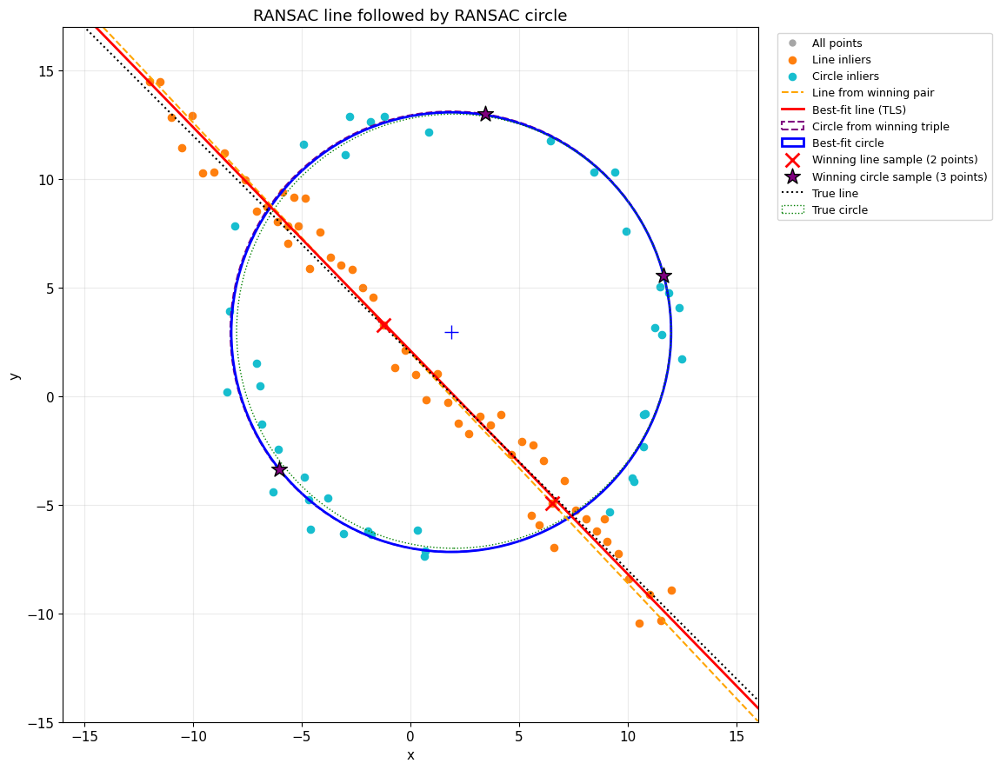

In [78]:
fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(X[:, 0], X[:, 1], c='0.65', s=25, label='All points')
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], c='tab:orange',
           s=35, label='Line inliers')
ax.scatter(X[circle_inliers, 0], X[circle_inliers, 1], c='tab:cyan',
           s=35, label='Circle inliers')

draw_line(ax, line_result['sample_model'], color='orange', linestyle='--',
          linewidth=1.5, label='Line from winning pair')
draw_line(ax, line_model, color='red', linewidth=2, label='Best-fit line (TLS)')

sample_xc, sample_yc, sample_r = circle_result['sample_model']
ax.add_patch(plt.Circle((sample_xc, sample_yc), sample_r, fill=False,
                        color='purple', linestyle='--', linewidth=1.5,
                        label='Circle from winning triple'))
ax.add_patch(plt.Circle((xc, yc), radius, fill=False, color='blue',
                        linewidth=2, label='Best-fit circle'))

line_sample = line_result['sample']
circle_sample = circle_result['sample']
ax.scatter(line_sample[:, 0], line_sample[:, 1], marker='x', c='red',
           s=130, linewidths=2, label='Winning line sample (2 points)', zorder=5)
ax.scatter(circle_sample[:, 0], circle_sample[:, 1], marker='*', c='purple',
           s=180, edgecolors='black', label='Winning circle sample (3 points)', zorder=5)

true_line = np.array([1, 1, 2]) / np.sqrt(2)
draw_line(ax, true_line, color='black', linestyle=':', label='True line')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, fill=False, color='green',
                        linestyle=':', label='True circle'))
ax.plot(xc, yc, '+', color='blue', markersize=12)
ax.set(xlim=(-16, 16), ylim=(-15, 17), xlabel='x', ylabel='y',
       title='RANSAC line followed by RANSAC circle')
ax.set_aspect('equal')
ax.grid(alpha=0.25)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
fig.tight_layout()
save_figure(fig, 'q2_line_and_circle.png')
plt.show()


### 2(d). What happens if the circle is fitted first?

#### 2(d).1 Fit the circle first and inspect its consensus

Use the known generating groups only to assess the result.


In [79]:
circle_first = ransac_circle(X, circle_threshold, 35, circle_n_trials, seed=12)
first_mask = circle_first['inliers']
first_xc, first_yc, first_radius = circle_first['model']

print('Circle fitted before removing the line:')
print(f'Centre = ({first_xc:.4f}, {first_yc:.4f}), radius = {first_radius:.4f}')
print(f'Circle-generated points in its consensus: {first_mask[:half_n].sum()} / {half_n}')
print(f'Line-generated points in its consensus: {first_mask[half_n:].sum()} / {half_n}')
print(f'Points left for a line fit: {(~first_mask).sum()}')


Circle fitted before removing the line:
Centre = (1.9461, 2.8866), radius = 10.1063
Circle-generated points in its consensus: 49 / 50
Line-generated points in its consensus: 8 / 50
Points left for a line fit: 43


#### 2(d).2 Fit the remaining line and plot the comparison

Check whether enough line points remain after removing the circle consensus.


Line consensus after fitting the circle first: 43


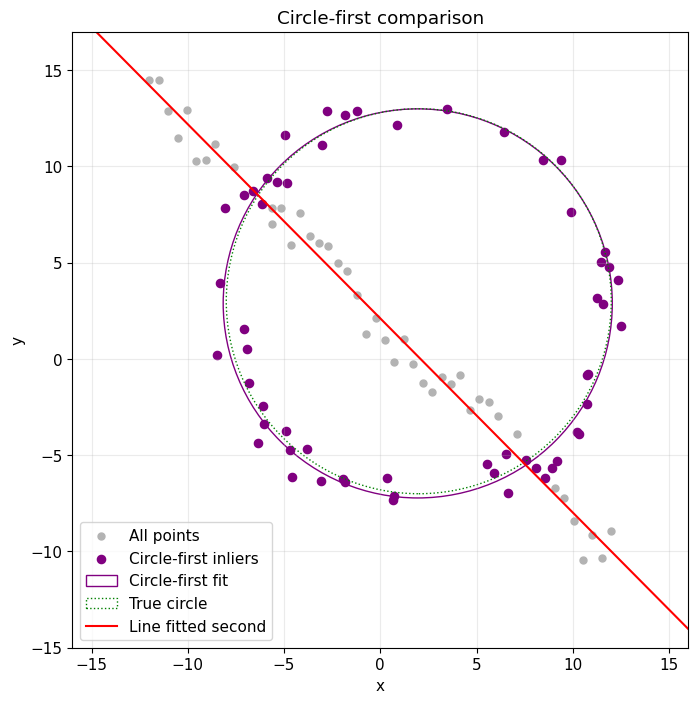

In [80]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X[:, 0], X[:, 1], c='0.7', s=25, label='All points')
ax.scatter(X[first_mask, 0], X[first_mask, 1], c='purple', s=35,
           label='Circle-first inliers')
ax.add_patch(plt.Circle((first_xc, first_yc), first_radius, fill=False,
                        color='purple', label='Circle-first fit'))
ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, fill=False, color='green',
                        linestyle=':', label='True circle'))

try:
    line_second = ransac_line(X[~first_mask], line_threshold,
                              line_min_inliers, line_n_trials, seed=13)
    draw_line(ax, line_second['model'], color='red', label='Line fitted second')
    print(f'Line consensus after fitting the circle first: {line_second["inliers"].sum()}')
except ValueError as error:
    print(f'The remaining points did not support the required line consensus: {error}')

ax.set(xlim=(-16, 16), ylim=(-15, 17), xlabel='x', ylabel='y',
       title='Circle-first comparison')
ax.set_aspect('equal')
ax.grid(alpha=0.25)
ax.legend()
save_figure(fig, 'q2_circle_first.png')
plt.show()


## 3. Homography and image blending


#### 3.1 Define the four-point selection function

The mouse callback and selection window stay in the same function.


In [81]:
def select_four_points(image, title, suggested_points=None):
    # Resize only the selection window. Convert clicks back to original coordinates.
    scale = min(1.0, 1000 / image.shape[1], 700 / image.shape[0])
    preview = cv.resize(image, None, fx=scale, fy=scale)
    scale_x = preview.shape[1] / image.shape[1]
    scale_y = preview.shape[0] / image.shape[0]
    if suggested_points is not None:
        guide = np.round(suggested_points * [scale_x, scale_y]).astype(np.int32)
        cv.polylines(preview, [guide], True, (0, 255, 0), 2)
        for i, (gx, gy) in enumerate(guide):
            cv.putText(preview, str(i + 1), (gx + 5, gy - 5),
                       cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    points = []
    window = title + ' - TL, TR, BR, BL | Enter: accept | R: reset | Esc: cancel'

    def mouse_callback(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
            points.append((x, y))

    cv.namedWindow(window, cv.WINDOW_AUTOSIZE)
    cv.setMouseCallback(window, mouse_callback)
    try:
        while True:
            canvas = preview.copy()
            for i, (x, y) in enumerate(points):
                cv.circle(canvas, (x, y), 5, (0, 0, 255), -1)
                cv.putText(canvas, str(i + 1), (x + 7, y - 7),
                           cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
            if len(points) > 1:
                cv.polylines(canvas, [np.array(points, dtype=np.int32)],
                             len(points) == 4, (0, 255, 0), 2)
            cv.imshow(window, canvas)
            key = cv.waitKey(20) & 0xFF
            if key in (10, 13) and len(points) == 4:
                break
            if key in (ord('r'), ord('R')):
                points.clear()
            if key == 27 or cv.getWindowProperty(window, cv.WND_PROP_VISIBLE) < 1:
                raise RuntimeError('Point selection cancelled.')
    finally:
        cv.destroyAllWindows()

    return np.float32(points) / np.float32([scale_x, scale_y])


#### 3.2 Define homography warping and blending

Map the source corners to the selected plane and blend using a separate mask.


In [82]:
def place_overlay(background, overlay, destination, alpha=0.8):
    destination = np.float32(destination)
    if destination.shape != (4, 2):
        raise ValueError('Four destination points are needed.')
    contour = destination.reshape(-1, 1, 2)
    if not cv.isContourConvex(contour) or abs(cv.contourArea(contour)) < 10:
        raise ValueError('Select a convex quadrilateral in TL, TR, BR, BL order.')

    source_height, source_width = overlay.shape[:2]
    source = np.float32([[0, 0], [source_width - 1, 0],
                         [source_width - 1, source_height - 1], [0, source_height - 1]])
    H = cv.getPerspectiveTransform(source, destination)
    height, width = background.shape[:2]

    warped = cv.warpPerspective(overlay, H, (width, height))
    source_mask = np.full((source_height, source_width), 255, dtype=np.uint8)
    mask = cv.warpPerspective(source_mask, H, (width, height),
                             flags=cv.INTER_NEAREST)

    # Warp the mask separately, so black parts of an overlay are retained.
    weight = alpha * (mask.astype(np.float32) / 255.0)[:, :, None]
    blended = (1 - weight) * background.astype(np.float32) + weight * warped.astype(np.float32)
    blended = np.clip(blended, 0, 255).astype(np.uint8)
    return blended, warped, mask, H


#### 3.3 Load the source and destination images

The default uses corrected stored coordinates. Set USE_MOUSE to True to select points using
the numbered guides and complete the manual-clicking step.


In [83]:
USE_MOUSE = False

building = read_image(image_dir / 'wadham.jpg')
flag = read_image(image_dir / 'flag.png')
flower_poster = read_image(image_dir / 'the_berry_farms_sunflower_field.jpeg')


#### 3.4 Set up the two image pairs

Each example stores its source image, destination corners and blending strength.


In [84]:
overlay_examples = [
    {
        'name': 'Flag on the left facade',
        'image': flag,
        'points': np.float32([[148, 207], [514, 283], [514, 529], [148, 526]]),
        'alpha': 0.80,
        'filename': 'q3_flag_overlay.png'
    },
    {
        'name': 'Sunflower poster on the left wall',
        'image': flower_poster,
        'points': np.float32([[189.87, 210.65], [297.43, 232.59], [285.36, 299.52], [193.17, 284.16]]),
        'alpha': 0.85,
        'filename': 'q3_sunflower_overlay.png'
    }
]


#### 3.5 Select corners and display each overlay

Use the stored planar regions by default. With USE_MOUSE enabled, click the numbered green
guides for each image pair. The output prints the selected points and homography.


Flag on the left facade
Destination points:
 [[148. 207.]
 [514. 283.]
 [514. 529.]
 [148. 526.]]
Homography (overlay to building):
 [[ 2.70207637e-01 -3.10405839e-17  1.48000000e+02]
 [ 8.33661672e-02  3.32638165e-01  2.07000000e+02]
 [ 1.54636773e-04 -2.94213628e-19  1.00000000e+00]]


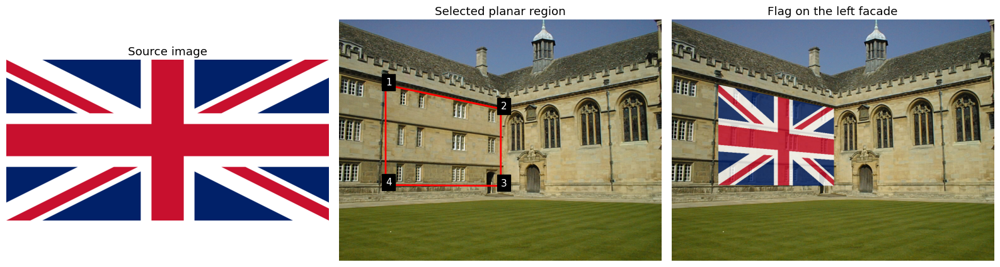

Sunflower poster on the left wall
Destination points:
 [[189.87 210.65]
 [297.43 232.59]
 [285.36 299.52]
 [193.17 284.16]]
Homography (overlay to building):
 [[8.67962826e-02 2.56983528e-02 1.89869995e+02]
 [2.46697377e-02 8.55138236e-02 2.10649994e+02]
 [4.05135097e-05 1.21163182e-04 1.00000000e+00]]


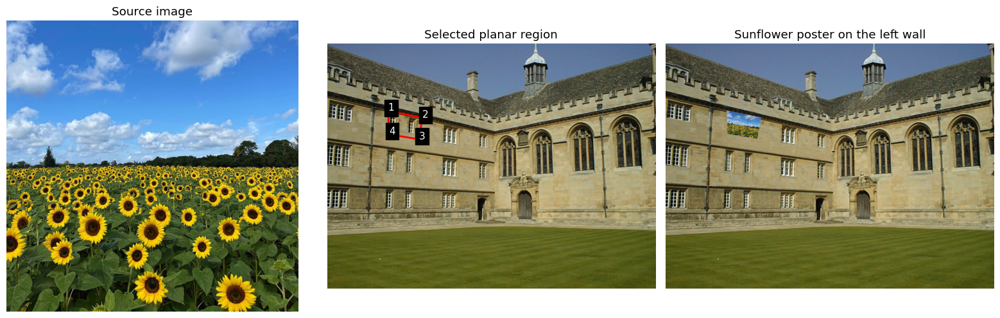

In [85]:
overlay_results = []
for example in overlay_examples:
    if USE_MOUSE:
        destination = select_four_points(building, example['name'], example['points'])
    else:
        destination = example['points']

    result, warped, mask, H = place_overlay(
        building, example['image'], destination, example['alpha']
    )
    overlay_results.append({'name': example['name'], 'image': result,
                            'points': destination, 'H': H})
    print(example['name'])
    print('Destination points:\n', np.round(destination, 2))
    print('Homography (overlay to building):\n', H)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    show_image(axes[0], example['image'], 'Source image')
    show_image(axes[1], building, 'Selected planar region')
    closed_points = np.vstack((destination, destination[0]))
    axes[1].plot(closed_points[:, 0], closed_points[:, 1], 'r-o', linewidth=2)
    for i, (x, y) in enumerate(destination):
        axes[1].text(x, y, str(i + 1), color='white', backgroundcolor='black')
    show_image(axes[2], result, example['name'])
    fig.tight_layout()
    save_figure(fig, example['filename'])
    plt.show()


**Discussion.** The homography changes the source image's perspective so its corners coincide with
the chosen quadrilateral. Inside the warped mask the blend is
$I_{out}=(1-\alpha)I_{building}+\alpha I_{overlay}$.
Outside the mask, the building stays unchanged.
An alpha below one lets the wall texture show through. A homography assumes a plane, so recessed
windows and parts that protrude from the facade will not have physically exact geometry.
The simple blend also does not simulate new shadows or illumination on the poster.

## 4. PCB alignment and difference images

### 4(a)-(c). SIFT, feature matching and alignment


#### 4(a).1 Read the template

All other PCB images will be aligned to AECC1.jpg.


In [86]:
pcb_dir = image_dir / 'pcbs'
template_path = pcb_dir / 'AECC1.jpg'
template = read_image(template_path)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)


#### 4(a).2 Detect SIFT features in the template

Keep its keypoints and descriptors for matching each input image.


In [87]:
sift = cv.SIFT_create()
template_keypoints, template_descriptors = sift.detectAndCompute(template_gray, None)
if template_descriptors is None or len(template_keypoints) < 4:
    raise ValueError('Not enough SIFT features in the template.')


#### 4(a).3 Display the template keypoints

Visualize the locations and scales returned by SIFT.


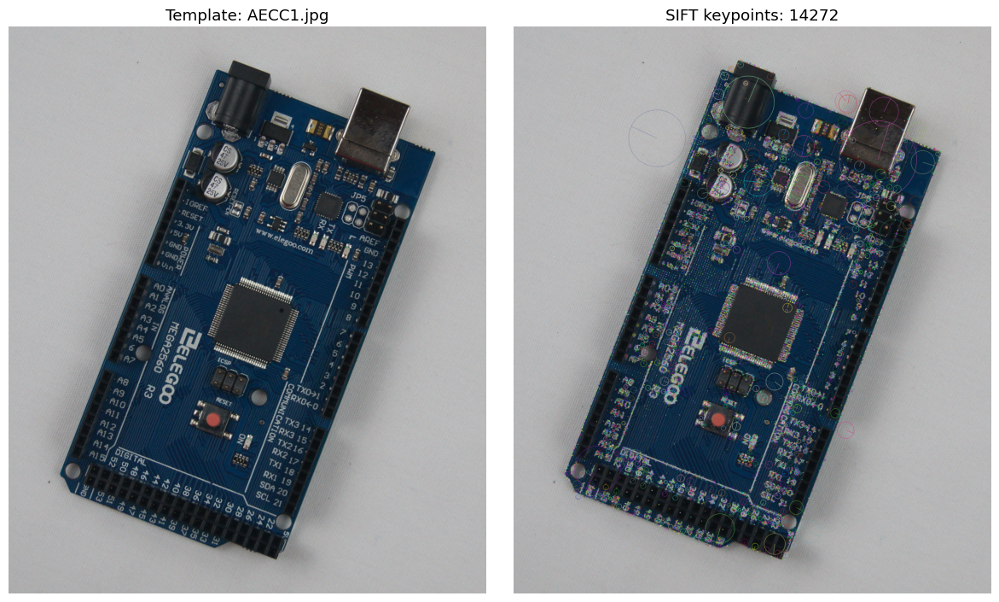

In [88]:
template_features = cv.drawKeypoints(
    template, template_keypoints, None,
    flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
show_image(axes[0], template, 'Template: AECC1.jpg')
show_image(axes[1], template_features, f'SIFT keypoints: {len(template_keypoints)}')
fig.tight_layout()
save_figure(fig, 'q4_template_sift.png')
plt.show()


#### 4(a).4 Define SIFT detection for an input image

This repeats the same detection step for a PCB photograph.


In [89]:
def detect_pcb_features(image):
    image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.detectAndCompute(image_gray, None)
    if descriptors is None or len(keypoints) < 4:
        raise ValueError('Not enough SIFT features in this image.')
    return image_gray, keypoints, descriptors


#### 4(b).1 Define descriptor matching and the ratio test

Compare each descriptor with the template and reject ambiguous matches.


In [90]:
def match_pcb_features(descriptors):
    matcher = cv.BFMatcher(cv.NORM_L2)
    pairs = matcher.knnMatch(descriptors, template_descriptors, k=2)
    good_matches = []
    for pair in pairs:
        if len(pair) == 2:
            first, second = pair
            if first.distance < 0.75 * second.distance:
                good_matches.append(first)
    good_matches.sort(key=lambda match: match.distance)

    if len(good_matches) < 4:
        raise ValueError(f'Only {len(good_matches)} matches passed the ratio test.')
    return good_matches


#### 4(b).2 Define homography estimation with RANSAC

Convert matched keypoints to coordinate pairs and estimate the mapping to the template.


In [91]:
def estimate_pcb_homography(keypoints, good_matches):
    source_points = np.float32([keypoints[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    target_points = np.float32([template_keypoints[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    H, inlier_mask = cv.findHomography(source_points, target_points, cv.RANSAC, 4.0)
    if H is None or inlier_mask is None or not np.all(np.isfinite(H)):
        raise ValueError('Homography estimation failed.')

    inlier_mask = inlier_mask.ravel().astype(bool)
    if inlier_mask.sum() < 4:
        raise ValueError('Fewer than four homography inliers.')
    return H, inlier_mask, source_points, target_points


#### 4(c).1 Define image warping and difference calculation

Warp the board, find the valid overlap and calculate absolute pixel differences.


In [92]:
def warp_pcb_and_difference(image, image_gray, H):
    height, width = template.shape[:2]
    aligned = cv.warpPerspective(image, H, (width, height))

    source_mask = np.full(image_gray.shape, 255, dtype=np.uint8)
    valid_mask = cv.warpPerspective(source_mask, H, (width, height),
                                    flags=cv.INTER_NEAREST)
    # Exclude a narrow edge where interpolation can mix image and border pixels.
    valid_mask = cv.erode(valid_mask, np.ones((3, 3), dtype=np.uint8))
    valid = valid_mask > 0
    if not valid.any():
        raise ValueError('The warped image has no overlap with the template.')

    difference = cv.absdiff(aligned, template)
    difference[~valid] = 0
    difference_gray = cv.cvtColor(difference, cv.COLOR_BGR2GRAY)
    mean_difference = float(difference[valid].mean())
    return aligned, valid_mask, valid, difference, difference_gray, mean_difference


#### 4(b)-(c). Check the fit and draw accepted matches

Measure the inlier reprojection error and draw up to 80 accepted matches.


In [93]:
def check_pcb_alignment(image, keypoints, good_matches, H, inlier_mask, source_points, target_points):
    projected = cv.perspectiveTransform(source_points[inlier_mask], H)
    reprojection_errors = np.linalg.norm(
        projected[:, 0, :] - target_points[inlier_mask, 0, :], axis=1
    )

    # Use every good match for estimation, but draw at most 80 accepted inliers for clarity.
    inlier_matches = [m for m, keep in zip(good_matches, inlier_mask) if keep]
    match_image = cv.drawMatches(
        image, keypoints, template, template_keypoints, inlier_matches[:80], None,
        matchColor=(0, 255, 0), flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    return reprojection_errors, match_image


#### Combine the PCB alignment steps

This short function calls the steps above in order and stores their results for each PCB.


In [94]:
def align_pcb(image):
    image_gray, keypoints, descriptors = detect_pcb_features(image)
    good_matches = match_pcb_features(descriptors)
    H, inlier_mask, source_points, target_points = estimate_pcb_homography(keypoints, good_matches)
    aligned, valid_mask, valid, difference, difference_gray, mean_difference = warp_pcb_and_difference(
        image, image_gray, H
    )
    reprojection_errors, match_image = check_pcb_alignment(
        image, keypoints, good_matches, H, inlier_mask, source_points, target_points
    )

    return {
        'H': H,
        'aligned': aligned,
        'difference': difference,
        'difference_gray': difference_gray,
        'valid_mask': valid_mask,
        'match_image': match_image,
        'keypoint_count': len(keypoints),
        'good_match_count': len(good_matches),
        'inlier_count': int(inlier_mask.sum()),
        'mean_difference': mean_difference,
        'overlap_percent': 100 * valid.mean(),
        'reprojection_rmse': float(np.sqrt(np.mean(reprojection_errors**2)))
    }


### 4(d). Process every supplied PCB image

#### 4(d).1 Find and align all PCB images

Store each successful alignment so the following cells can display it without recomputing SIFT.


In [95]:
pcb_paths = sorted(path for path in pcb_dir.glob('*.jpg') if path.name != template_path.name)
if not pcb_paths:
    raise FileNotFoundError('No PCB images were found apart from the template.')

pcb_results = {}
pcb_failures = {}

for path in pcb_paths:
    image = read_image(path)
    try:
        result = align_pcb(image)
    except (ValueError, cv.error) as error:
        pcb_failures[path.name] = str(error)
        print(f'{path.name}: alignment failed - {error}')
        continue

    pcb_results[path.name] = result
    print(f'\n{path.name}: {result["good_match_count"]} ratio-test matches, '
          f'{result["inlier_count"]} RANSAC inliers')
    print(f'Reprojection RMSE: {result["reprojection_rmse"]:.3f} pixels')
    print(f'Valid overlap: {result["overlap_percent"]:.1f}%')
    print(f'Mean absolute RGB-channel difference: {result["mean_difference"]:.3f} / 255')
    print('Homography (input to template):\n', result['H'])



AAAA1.jpg: 51 ratio-test matches, 17 RANSAC inliers
Reprojection RMSE: 2.059 pixels
Valid overlap: 88.8%
Mean absolute RGB-channel difference: 29.135 / 255
Homography (input to template):
 [[ 1.18471157e+00 -1.10146759e+00  1.04740107e+03]
 [ 6.30688379e-01  9.47681491e-01 -3.09498515e+02]
 [ 2.29504662e-05 -7.02219946e-05  1.00000000e+00]]

ADAD1.jpg: 369 ratio-test matches, 193 RANSAC inliers
Reprojection RMSE: 1.217 pixels
Valid overlap: 98.0%
Mean absolute RGB-channel difference: 30.690 / 255
Homography (input to template):
 [[ 1.23489975e+00 -1.51865715e-02 -6.25266975e+01]
 [ 1.45361079e-01  1.05663530e+00 -1.54214823e+02]
 [ 5.32794972e-05  5.29653546e-06  1.00000000e+00]]

AECC2.jpg: 4322 ratio-test matches, 3839 RANSAC inliers
Reprojection RMSE: 0.648 pixels
Valid overlap: 98.4%
Mean absolute RGB-channel difference: 3.520 / 255
Homography (input to template):
 [[ 1.00061008e+00 -1.50343341e-02  3.20800275e+01]
 [ 1.65970603e-02  1.00003437e+00 -1.81867146e+01]
 [ 3.53394326e-

#### 4(d).2 Display feature matches for every PCB

The input image appears on the left and the template on the right.


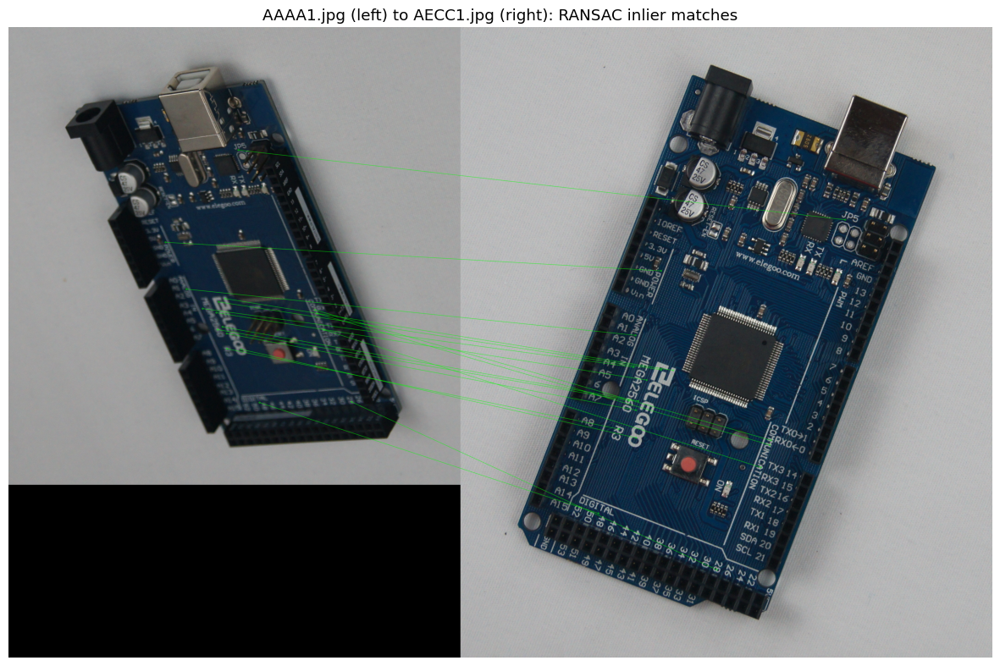

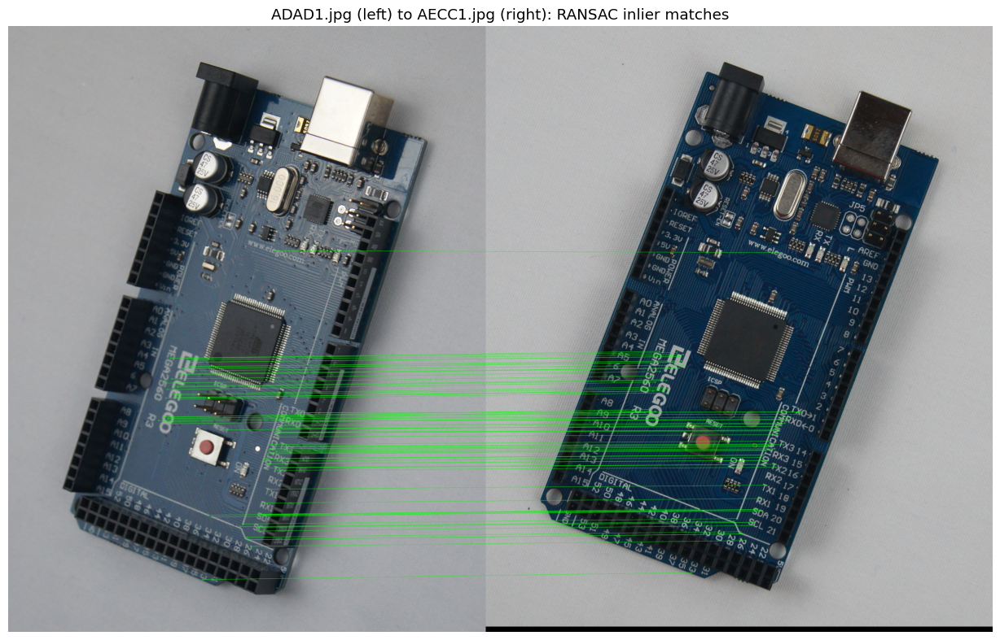

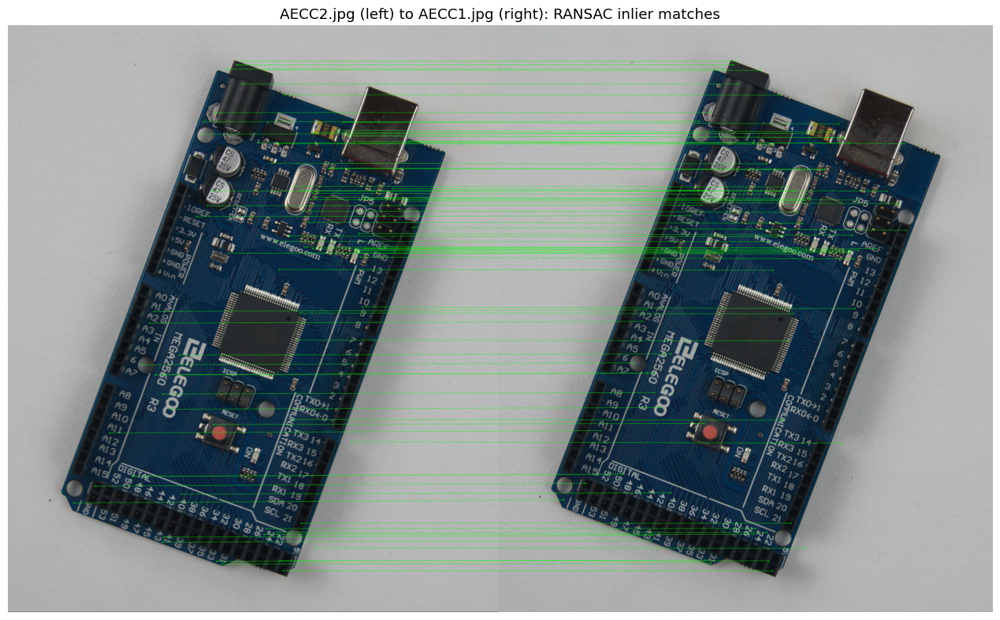

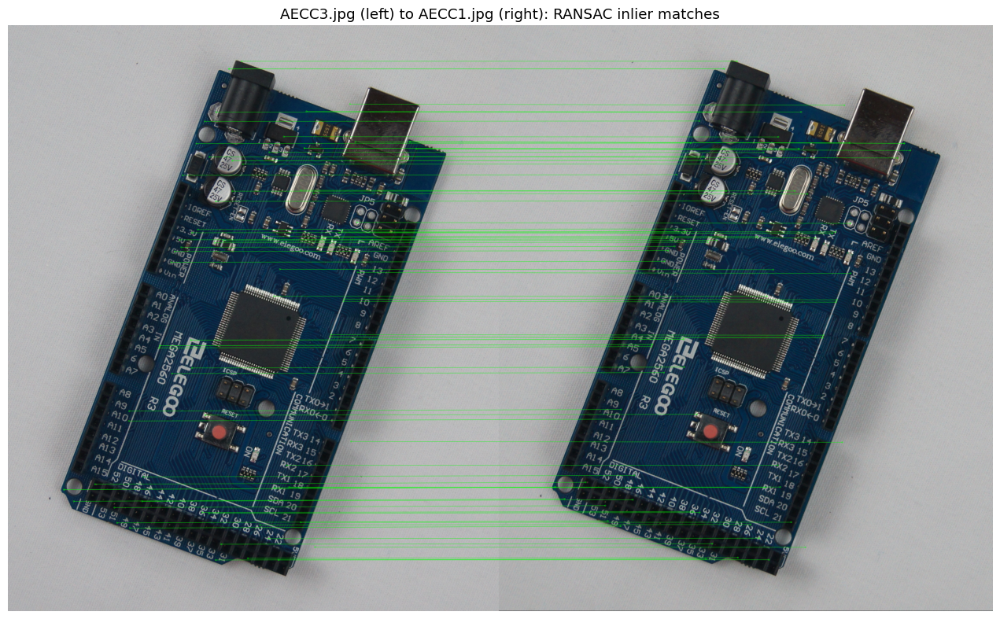

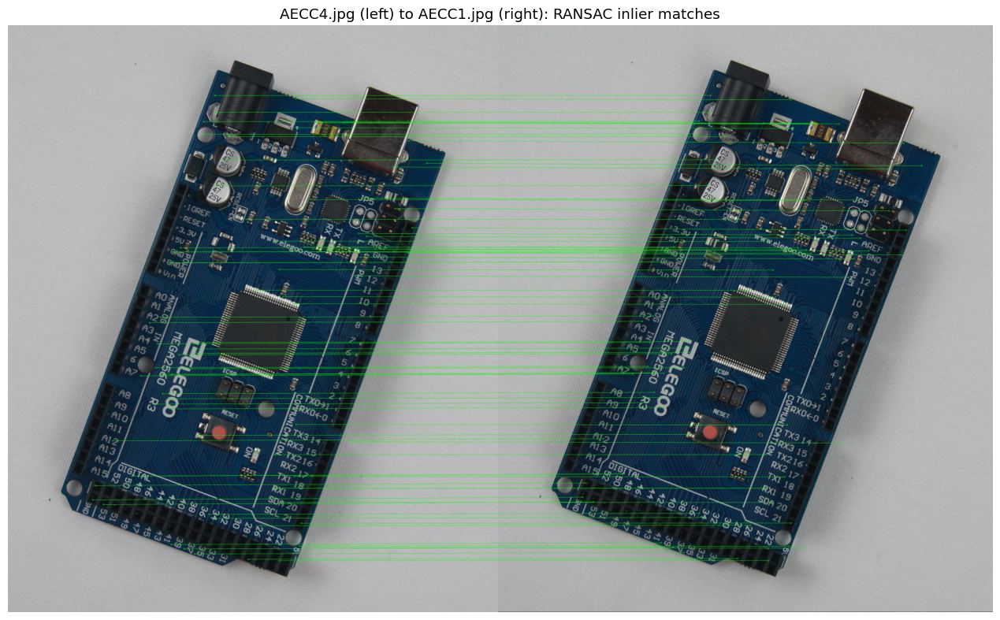

In [96]:
for name, result in pcb_results.items():
    path = pcb_dir / name
    fig, ax = plt.subplots(figsize=(14, 8))
    show_image(ax, result['match_image'], f'{path.name} (left) to AECC1.jpg (right): RANSAC inlier matches')
    fig.tight_layout()
    save_figure(fig, f'q4_{path.stem}_matches.png')
    plt.show()


#### 4(d).3 Display aligned boards and their differences

Show each comparison and optionally save the difference image and overlap mask.


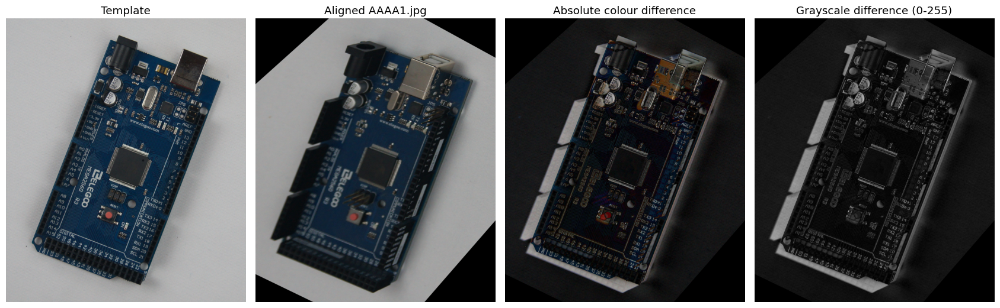

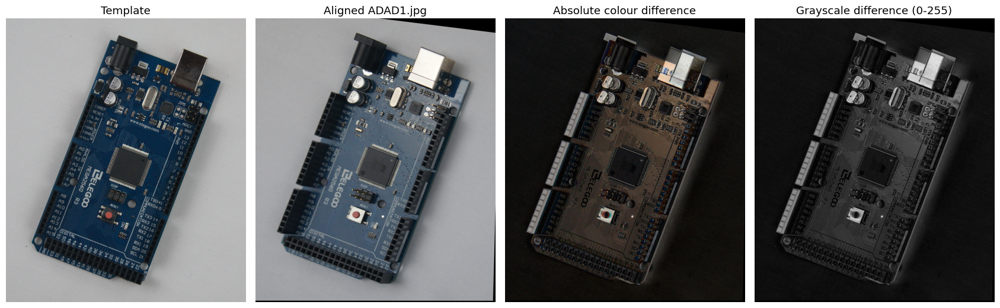

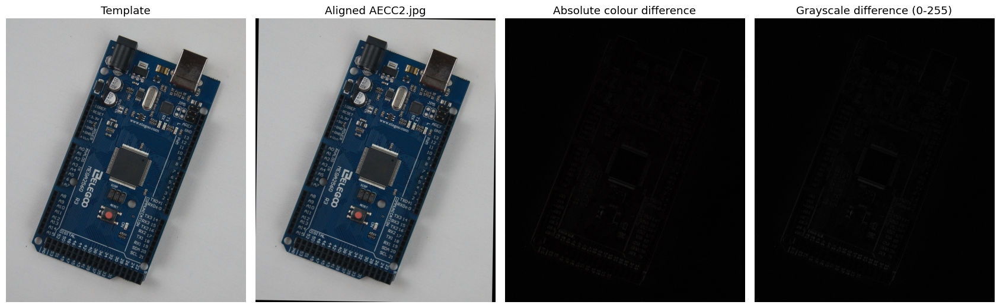

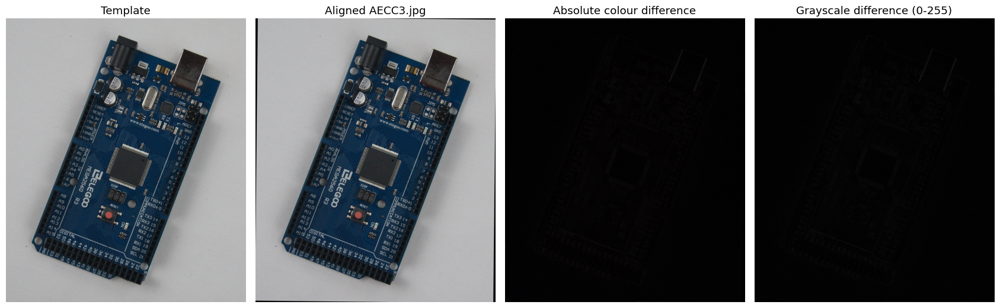

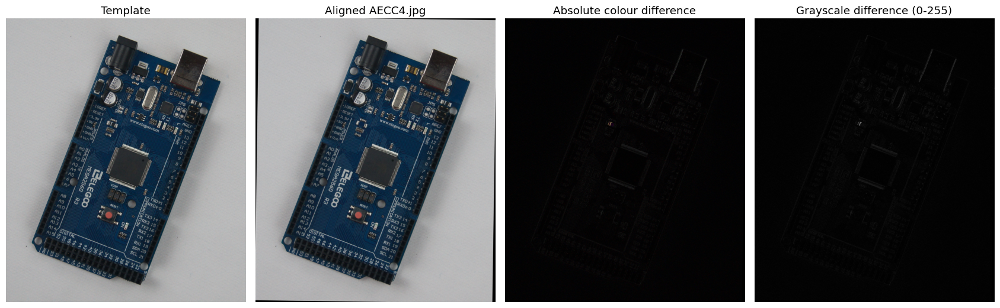

In [97]:
for name, result in pcb_results.items():
    path = pcb_dir / name
    fig, axes = plt.subplots(1, 4, figsize=(17, 6))
    show_image(axes[0], template, 'Template')
    show_image(axes[1], result['aligned'], f'Aligned {path.name}')
    show_image(axes[2], result['difference'], 'Absolute colour difference')
    show_image(axes[3], result['difference_gray'], 'Grayscale difference (0-255)')
    fig.tight_layout()
    save_figure(fig, f'q4_{path.stem}_alignment.png')
    plt.show()

    if SAVE_FIGURES:
        cv.imwrite(str(output_dir / f'q4_{path.stem}_difference.png'), result['difference'])
        cv.imwrite(str(output_dir / f'q4_{path.stem}_valid_mask.png'), result['valid_mask'])


#### 4(d).4 Compare alignment statistics

List matches, inliers, geometric error, overlap and average difference.


In [98]:
print(f'{"Image":<13} {"Matches":>8} {"Inliers":>8} {"RMSE (px)":>11} {"Overlap %":>11} {"Mean diff":>11}')
for name, result in pcb_results.items():
    print(f'{name:<13} {result["good_match_count"]:>8} {result["inlier_count"]:>8} '
          f'{result["reprojection_rmse"]:>11.3f} {result["overlap_percent"]:>11.1f} '
          f'{result["mean_difference"]:>11.3f}')

if pcb_failures:
    print('\nImages still needing a successful alignment:')
    for name, reason in pcb_failures.items():
        print(f'{name}: {reason}')


Image          Matches  Inliers   RMSE (px)   Overlap %   Mean diff
AAAA1.jpg           51       17       2.059        88.8      29.135
ADAD1.jpg          369      193       1.217        98.0      30.690
AECC2.jpg         4322     3839       0.648        98.4       3.520
AECC3.jpg         5629     5001       0.591        98.9       3.295
AECC4.jpg         3830     3396       0.690        98.5       4.066


#### 4(d).5 Show all difference images together

Use the same intensity scale for every image.


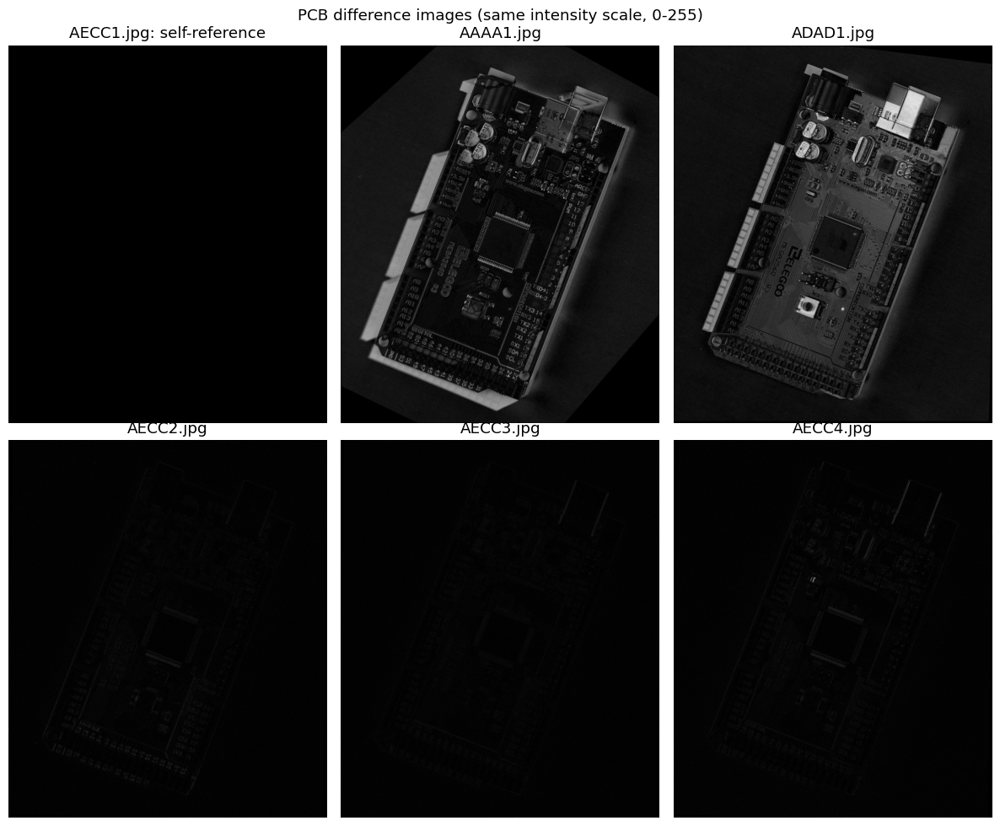

In [99]:
overview_names = [template_path.name] + [path.name for path in pcb_paths]
columns = 3
rows = int(np.ceil(len(overview_names) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(12, 5 * rows), squeeze=False)

for ax, name in zip(axes.flat, overview_names):
    if name == template_path.name:
        show_image(ax, np.zeros_like(template_gray), 'AECC1.jpg: self-reference')
    elif name in pcb_results:
        show_image(ax, pcb_results[name]['difference_gray'], name)
    else:
        ax.text(0.5, 0.5, f'{name}\nAlignment failed', ha='center', va='center')
        ax.axis('off')

for ax in axes.flat[len(overview_names):]:
    ax.axis('off')
fig.suptitle('PCB difference images (same intensity scale, 0-255)')
fig.tight_layout()
save_figure(fig, 'q4_all_difference_images.png')
plt.show()


### 4(e). Why do the USB port, capacitors and reset button show high differences?
